# Mixed Rank + Expert Follow-Up Significance Analysis

This notebook analyzes the longer mixed follow-up runs from the single trusted report:

`outputs/pipeline_runs/moe_study_expert_sweep_pipeline_report/mix_follow_up_report.xlsx`

Question: which remaining concrete approach works best? We first rank all complete follow-up configs, then use Friedman tests with Holm correction and Wilcoxon signed-rank post-hoc tests among the top 4 configs.

In [1]:
# first we load the data. The Excel report is the single source of trust here.
from pathlib import Path
from itertools import combinations
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import friedmanchisquare, wilcoxon

ROOT = next(
    path for path in [Path.cwd(), *Path.cwd().parents]
    if (path / "configs/pipeline").exists() and (path / "outputs/pipeline_runs").exists()
)
REPORT = ROOT / "outputs/pipeline_runs/moe_study_expert_sweep_pipeline_report/mix_follow_up_report.xlsx"

xls = pd.ExcelFile(REPORT)
raw = pd.read_excel(REPORT, sheet_name="benchmark_raw")
configs = pd.read_excel(REPORT, sheet_name="run_configs")

primary = raw[
  ((raw.benchmark == "Belebele") & (raw.metric == "acc_norm")) |
  ((raw.benchmark == "FLORES") & (raw.metric.astype(str).str.startswith("bits_per_byte "))) |
  ((raw.benchmark == "SIB200") & (raw.metric == "acc")) |
  ((raw.benchmark == "Taxi1500") & (raw.metric == "acc"))
].copy()
primary = primary[~primary["is_baseline"].astype(str).str.lower().isin(["true", "1", "yes"])]

print(REPORT)
print("sheets:", xls.sheet_names)
print("primary rows:", len(primary), "runs:", primary.run_id.nunique())
primary.head()

/scratch/hpc-prf-merlin/joel/moe-study/outputs/pipeline_runs/moe_study_expert_sweep_pipeline_report/mix_follow_up_report.xlsx
sheets: ['benchmark_compact', 'data_overview', 'run_configs', 'pipeline_profile', 'benchmark_raw', 'experiment_meta']
primary rows: 588 runs: 14


,run_id,kind,benchmark,task,language,resource_availability,metric,better,value,is_baseline
1,hydralora_r2_heads2,hydralora,Belebele,belebele_arb_Arab,arb_Arab,HIGH,acc_norm,higher,0.602222,False
2,hydralora_r2_heads32,hydralora,Belebele,belebele_arb_Arab,arb_Arab,HIGH,acc_norm,higher,0.596667,False
3,hydralora_r4_heads2,hydralora,Belebele,belebele_arb_Arab,arb_Arab,HIGH,acc_norm,higher,0.541111,False
4,lora_r4,lora,Belebele,belebele_arb_Arab,arb_Arab,HIGH,acc_norm,higher,0.558889,False
5,moelora_tr128_e32_k4,moelora,Belebele,belebele_arb_Arab,arb_Arab,HIGH,acc_norm,higher,0.586667,False


## Prepare Paired Metric Table

We keep only complete runs for the confirmatory comparison. A complete run has all 42 primary metric rows: 9 Belebele, 18 FLORES directions, 9 SIB200, and 6 Taxi1500.

In [2]:
# here we prepare our df for analysis and normalize the scores

def parse_total_rank(run_id):
    run_id = str(run_id)
    m = re.search(r"_tr(\d+)_", run_id)
    if m:
        return int(m.group(1))
    m = re.search(r"_r(\d+)(?:_|$)", run_id)
    return int(m.group(1)) if m else np.nan


def parse_component_count(run_id):
    run_id = str(run_id)
    for pat in [r"_e(\d+)(?:_|$)", r"_heads(\d+)$", r"_nup(\d+)$", r"_b(\d+)$"]:
        m = re.search(pat, run_id)
        if m:
            return int(m.group(1))
    return np.nan


def parse_top_k(run_id):
    m = re.search(r"_k(\d+)(?:_|$)", str(run_id))
    return int(m.group(1)) if m else np.nan

metrics = primary.copy()
metrics["direction"] = metrics.metric.astype(str).str.extract(r"(en->x|x->en)", expand=False).fillna("")
metrics["score_family"] = np.where(metrics.benchmark.eq("FLORES"), "FLORES " + metrics.direction, metrics.benchmark)
metrics["total_rank"] = metrics.run_id.map(parse_total_rank)
metrics["component_count"] = metrics.run_id.map(parse_component_count)
metrics["top_k"] = metrics.run_id.map(parse_top_k)
metrics["value"] = pd.to_numeric(metrics.value, errors="coerce")

coverage = (
    metrics.groupby(["run_id", "kind"], dropna=False)
    .agg(primary_rows=("value", "count"), score_families=("score_family", "nunique"), tasks=("task", "nunique"))
    .reset_index()
    .sort_values(["primary_rows", "run_id"], ascending=[False, True])
)
expected_rows = int(coverage.primary_rows.max())
complete_runs = coverage.loc[coverage.primary_rows.eq(expected_rows), "run_id"].tolist()
excluded_runs = coverage.loc[~coverage.primary_rows.eq(expected_rows)].copy()

metrics = metrics[metrics.run_id.isin(complete_runs)].dropna(subset=["value"]).copy()

# Min-max normalization within each paired task/metric unit. Higher is always better after this.
g = metrics.groupby(["score_family", "task", "metric"]).value
lo, hi = g.transform("min"), g.transform("max")
metrics["normalized_score"] = np.where(metrics.better.eq("lower"), (hi - metrics.value) / (hi - lo), (metrics.value - lo) / (hi - lo))
metrics.loc[(hi - lo).eq(0), "normalized_score"] = 1.0

print("complete runs used:", len(complete_runs), "expected rows per run:", expected_rows)
print("excluded incomplete runs:", excluded_runs.run_id.tolist())
display(coverage)

complete runs used: 14 expected rows per run: 42
excluded incomplete runs: []


,run_id,kind,primary_rows,score_families,tasks
0,hydralora_r2_heads2,hydralora,42,5,42
1,hydralora_r2_heads32,hydralora,42,5,42
2,hydralora_r4_heads2,hydralora,42,5,42
3,lora_r4,lora,42,5,42
4,moelora_tr128_e32_k4,moelora,42,5,42
5,moelora_tr128_e32_k8,moelora,42,5,42
6,moelora_tr4_e2_k1,moelora,42,5,42
7,moelora_tr64_e32_k4,moelora,42,5,42
8,moelora_tr64_e32_k8,moelora,42,5,42
9,moelora_tr8_e2_k1,moelora,42,5,42


## Descriptive Top Configs

Top configs by mean normalized score


,run_id,kind,total_rank,component_count,top_k,mean_score,n_rows,mean_belebele,mean_flores,mean_sib,mean_taxi
0,hydralora_r2_heads32,hydralora,2.0,32.0,NaN,0.801961,42,0.703113,0.920397,0.929266,0.403971
1,moelora_tr64_e32_k8,moelora,64.0,32.0,8.0,0.799617,42,0.937030,0.796948,0.750555,0.675099
2,moelora_tr64_e32_k4,moelora,64.0,32.0,4.0,0.789081,42,0.896309,0.875772,0.608463,0.639093
3,moelora_tr128_e32_k8,moelora,128.0,32.0,8.0,0.765262,42,0.668660,0.770597,0.773767,0.881405
4,mola_tr64_e32_k4,mola,64.0,32.0,4.0,0.721210,42,0.776160,0.789778,0.640654,0.553917
5,hydralora_r2_heads2,hydralora,2.0,2.0,NaN,0.708734,42,0.830053,0.712846,0.546331,0.758021
6,mov_dense_e2,movlora,NaN,2.0,NaN,0.632994,42,0.669235,0.590147,0.945026,0.239125
7,moelora_tr8_e2_k1,moelora,8.0,2.0,1.0,0.584838,42,0.434064,0.744580,0.633042,0.259465
8,moelora_tr128_e32_k4,moelora,128.0,32.0,4.0,0.578661,42,0.689511,0.728891,0.282713,0.405622
9,mola_tr4_e2_k1,mola,4.0,2.0,1.0,0.554946,42,0.623588,0.601677,0.655539,0.160902


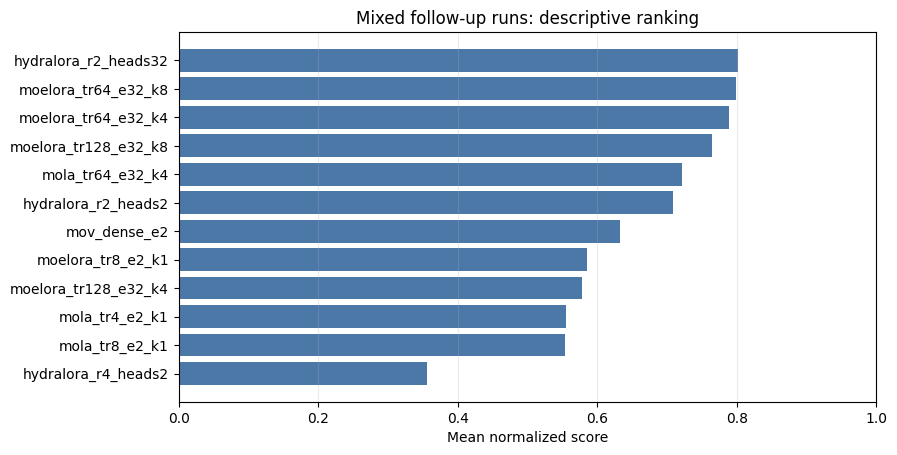

In [3]:
config_summary = (
    metrics.groupby(["run_id", "kind", "total_rank", "component_count", "top_k"], dropna=False)
    .agg(
        mean_score=("normalized_score", "mean"),
        n_rows=("normalized_score", "count"),
        mean_belebele=("normalized_score", lambda s: s[metrics.loc[s.index, "benchmark"].eq("Belebele")].mean()),
        mean_flores=("normalized_score", lambda s: s[metrics.loc[s.index, "benchmark"].eq("FLORES")].mean()),
        mean_sib=("normalized_score", lambda s: s[metrics.loc[s.index, "benchmark"].eq("SIB200")].mean()),
        mean_taxi=("normalized_score", lambda s: s[metrics.loc[s.index, "benchmark"].eq("Taxi1500")].mean()),
    )
    .sort_values("mean_score", ascending=False)
    .reset_index()
)

print("Top configs by mean normalized score")
display(config_summary.head(10))

fig, ax = plt.subplots(figsize=(9, 4.8))
top = config_summary.head(12).iloc[::-1]
ax.barh(top.run_id, top.mean_score, color="#4C78A8")
ax.set(xlabel="Mean normalized score", title="Mixed follow-up runs: descriptive ranking", xlim=(0, 1))
ax.grid(axis="x", alpha=0.25)
plt.show()

## Friedman + Holm Significance Tests

The Friedman test compares concrete run configs as paired treatments over the same task/metric units. We correct the per-family Friedman p-values with Holm. The overall test is a single omnibus test, so its Holm value equals the raw p-value.

In [4]:
def holm(pvals):
    pvals = np.asarray(pd.Series(pvals, dtype=float), dtype=float)
    adjusted = np.full(len(pvals), np.nan, dtype=float)
    valid = np.where(np.isfinite(pvals))[0]
    if len(valid) == 0:
        return adjusted
    order = valid[np.argsort(pvals[valid])]
    raw_adj = np.empty(len(order), dtype=float)
    m = len(order)
    for rank, idx in enumerate(order):
        raw_adj[rank] = min((m - rank) * pvals[idx], 1.0)
    raw_adj = np.maximum.accumulate(raw_adj)
    for idx, value in zip(order, raw_adj):
        adjusted[idx] = value
    return adjusted


def config_pivot(df, group_cols):
    return (
        df.groupby(group_cols + ["run_id"])["normalized_score"]
        .mean()
        .unstack("run_id")
        .dropna()
    )


def friedman_configs(df, label, group_cols):
    pivot = config_pivot(df, group_cols)
    configs_order = list(pivot.columns)
    stat, p = friedmanchisquare(*[pivot[c] for c in configs_order])
    avg_ranks = pivot.rank(axis=1, ascending=False).mean().sort_values()
    ordered = avg_ranks.index.tolist()
    return {
        "analysis": label,
        "pivot": pivot,
        "top3_configs": ordered[:3],
        "top4_configs": ordered[:4],
        "n_pairs": len(pivot),
        "n_configs": len(configs_order),
        "friedman_p_raw": p,
        "kendalls_w": stat / (len(pivot) * (pivot.shape[1] - 1)),
        **{f"avg_rank_{c}": avg_ranks.get(c, np.nan) for c in ordered},
    }


def friedman_by_family(df):
    rows = []
    for score_family, g in df.groupby("score_family"):
        result = friedman_configs(g, score_family, ["task", "language", "metric"])
        rows.append({k: v for k, v in result.items() if k != "pivot"})
    out = pd.DataFrame(rows)
    out["p_holm"] = holm(out["friedman_p_raw"])
    out["significant"] = out["p_holm"] < 0.05
    return out


def wilcoxon_top4(result):
    pivot = result["pivot"]
    top4 = result["top4_configs"]
    rows = []
    # Compare all pairs among top 1-4 in the Friedman order. Direction is higher-ranked > lower-ranked.
    for a, b in combinations(top4, 2):
        w = wilcoxon(pivot[a], pivot[b], zero_method="pratt", alternative="greater")
        rows.append({
            "analysis": result["analysis"],
            "a": a,
            "b": b,
            "mean_a": pivot[a].mean(),
            "mean_b": pivot[b].mean(),
            "median_delta_a_minus_b": (pivot[a] - pivot[b]).median(),
            "n_pairs": len(pivot),
            "p_raw": w.pvalue,
        })
    out = pd.DataFrame(rows)
    out["p_holm"] = holm(out["p_raw"])
    out["significant"] = out["p_holm"] < 0.05
    return out


overall = friedman_configs(metrics, "overall", ["score_family", "task", "language", "metric"])
overall_summary = pd.DataFrame([{k: v for k, v in overall.items() if k != "pivot"}])
overall_summary["p_holm"] = holm(overall_summary["friedman_p_raw"])
overall_summary["significant"] = overall_summary["p_holm"] < 0.05

family_friedman = friedman_by_family(metrics)
top4_wilcoxon = wilcoxon_top4(overall)

print("Overall Friedman result")
display(overall_summary)
print("Per-family Friedman results with Holm correction")
display(family_friedman)
print("Wilcoxon signed-rank post-hoc among top 1-4 configs with Holm correction")
display(top4_wilcoxon)

Overall Friedman result


,analysis,top3_configs,top4_configs,n_pairs,n_configs,friedman_p_raw,kendalls_w,avg_rank_moelora_tr64_e32_k4,avg_rank_hydralora_r2_heads32,avg_rank_moelora_tr64_e32_k8,...,avg_rank_mov_dense_e2,avg_rank_moelora_tr8_e2_k1,avg_rank_moelora_tr128_e32_k4,avg_rank_mola_tr8_e2_k1,avg_rank_mola_tr4_e2_k1,avg_rank_hydralora_r4_heads2,avg_rank_moelora_tr4_e2_k1,avg_rank_lora_r4,p_holm,significant
0,overall,"[moelora_tr64_e32_k4, hydralora_r2_heads32, mo...","[moelora_tr64_e32_k4, hydralora_r2_heads32, mo...",42,14,6.933930e-45,0.448747,4.22619,4.238095,4.380952,...,7.011905,7.607143,8.095238,8.27381,8.52381,10.952381,11.630952,12.904762,6.933930e-45,True


Per-family Friedman results with Holm correction


,analysis,top3_configs,top4_configs,n_pairs,n_configs,friedman_p_raw,kendalls_w,avg_rank_moelora_tr64_e32_k8,avg_rank_moelora_tr64_e32_k4,avg_rank_hydralora_r2_heads2,...,avg_rank_mov_dense_e2,avg_rank_moelora_tr128_e32_k4,avg_rank_mola_tr4_e2_k1,avg_rank_moelora_tr4_e2_k1,avg_rank_moelora_tr8_e2_k1,avg_rank_mola_tr8_e2_k1,avg_rank_hydralora_r4_heads2,avg_rank_lora_r4,p_holm,significant
0,Belebele,"[moelora_tr64_e32_k8, moelora_tr64_e32_k4, hyd...","[moelora_tr64_e32_k8, moelora_tr64_e32_k4, hyd...",9,14,2.251388e-11,0.669664,2.444444,2.888889,3.888889,...,6.833333,6.888889,7.833333,9.611111,10.111111,11.222222,11.611111,13.833333,6.754164e-11,True
1,FLORES en->x,"[moelora_tr64_e32_k4, moelora_tr8_e2_k1, moelo...","[moelora_tr64_e32_k4, moelora_tr8_e2_k1, moelo...",9,14,1.084625e-12,0.729318,4.111111,3.222222,8.111111,...,10.333333,5.777778,9.333333,12.222222,3.444444,6.555556,12.222222,14.000000,4.338501e-12,True
2,FLORES x->en,"[hydralora_r2_heads32, moelora_tr64_e32_k4, mo...","[hydralora_r2_heads32, moelora_tr64_e32_k4, mo...",9,14,3.733560e-11,0.659639,6.222222,2.666667,5.888889,...,6.666667,7.444444,8.666667,13.000000,9.000000,8.444444,10.444444,13.666667,7.467121e-11,True
3,SIB200,"[mov_dense_e2, hydralora_r2_heads32, moelora_t...","[mov_dense_e2, hydralora_r2_heads32, moelora_t...",9,14,4.312074e-13,0.747320,5.000000,7.777778,8.444444,...,1.611111,12.111111,5.888889,13.277778,6.611111,7.000000,12.055556,11.166667,2.156037e-12,True
4,Taxi1500,"[moelora_tr128_e32_k8, hydralora_r2_heads2, mo...","[moelora_tr128_e32_k8, hydralora_r2_heads2, mo...",6,14,5.626511e-05,0.543627,4.000000,4.750000,3.500000,...,10.916667,8.333333,12.083333,9.250000,9.500000,8.083333,7.166667,11.333333,5.626511e-05,True


Wilcoxon signed-rank post-hoc among top 1-4 configs with Holm correction


,analysis,a,b,mean_a,mean_b,median_delta_a_minus_b,n_pairs,p_raw,p_holm,significant
0,overall,moelora_tr64_e32_k4,hydralora_r2_heads32,0.789081,0.801961,-0.007033,42,0.660061,1.000000,False
1,overall,moelora_tr64_e32_k4,moelora_tr64_e32_k8,0.789081,0.799617,0.004662,42,0.529904,1.000000,False
2,overall,moelora_tr64_e32_k4,moelora_tr128_e32_k8,0.789081,0.765262,0.053362,42,0.185655,0.742622,False
3,overall,hydralora_r2_heads32,moelora_tr64_e32_k8,0.801961,0.799617,0.005293,42,0.460160,1.000000,False
4,overall,hydralora_r2_heads32,moelora_tr128_e32_k8,0.801961,0.765262,0.061862,42,0.082562,0.478240,False
5,overall,moelora_tr64_e32_k8,moelora_tr128_e32_k8,0.799617,0.765262,0.029935,42,0.079707,0.478240,False


## Answer

In [5]:
top3 = overall["top3_configs"]
top4 = overall["top4_configs"]
print("Top 3 configs by Friedman average rank:")
for i, run_id in enumerate(top3, start=1):
    row = config_summary[config_summary.run_id.eq(run_id)].iloc[0]
    print(f"{i}. {run_id} | kind={row.kind} | mean_score={row.mean_score:.4f} | total_rank={row.total_rank} | components={row.component_count} | top_k={row.top_k}")

print("\nTop 4 configs used for Wilcoxon post-hoc:", top4)
print("Overall Friedman significant:", bool(overall_summary.significant.iloc[0]), "p_holm=", overall_summary.p_holm.iloc[0])

sig_pairs = top4_wilcoxon[top4_wilcoxon.significant]
print("Significant top-4 Wilcoxon pairs:")
if sig_pairs.empty:
    print("none")
else:
    for r in sig_pairs.itertuples(index=False):
        print(f"{r.a} > {r.b}: p_holm={r.p_holm:.4g}, median_delta={r.median_delta_a_minus_b:.4f}")


Top 3 configs by Friedman average rank:
1. moelora_tr64_e32_k4 | kind=moelora | mean_score=0.7891 | total_rank=64.0 | components=32.0 | top_k=4.0
2. hydralora_r2_heads32 | kind=hydralora | mean_score=0.8020 | total_rank=2.0 | components=32.0 | top_k=nan
3. moelora_tr64_e32_k8 | kind=moelora | mean_score=0.7996 | total_rank=64.0 | components=32.0 | top_k=8.0

Top 4 configs used for Wilcoxon post-hoc: ['moelora_tr64_e32_k4', 'hydralora_r2_heads32', 'moelora_tr64_e32_k8', 'moelora_tr128_e32_k8']
Overall Friedman significant: True p_holm= 6.933930377857454e-45
Significant top-4 Wilcoxon pairs:
none
